## STEP 1.Importing the libraries

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import *

RANDOM_STATE = 42
TRAIN_PATH = "train.csv"
TEST_PATH = "test.csv"


train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("dim of the train:", train_df.shape)
print("dim of the test:", test_df.shape)

dim of the train: (76518, 38)
dim of the test: (51012, 37)


In [11]:
train_df.head(10)

,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,0,1,1,1,9238,1,1,126.0,1,1,...,0,6,7,6,12.428571,0,11.1,0.6,2.02,Graduate
1,1,1,17,1,9238,1,1,125.0,1,19,...,0,6,9,0,0.000000,0,11.1,0.6,2.02,Dropout
2,2,1,17,2,9254,1,1,137.0,1,3,...,0,6,0,0,0.000000,0,16.2,0.3,-0.92,Dropout
3,3,1,1,3,9500,1,1,131.0,1,19,...,0,8,11,7,12.820000,0,11.1,0.6,2.02,Enrolled
4,4,1,1,2,9500,1,1,132.0,1,19,...,0,7,12,6,12.933333,0,7.6,2.6,0.32,Graduate
5,5,1,39,1,171,1,19,133.1,1,19,...,0,0,0,0,0.000000,0,13.9,-0.3,0.79,Dropout
6,6,1,44,1,9085,1,39,130.0,1,37,...,0,5,8,5,13.250000,0,12.4,0.5,1.79,Graduate
7,7,1,1,1,9773,1,1,130.0,1,19,...,0,6,6,6,13.666667,0,10.8,1.4,1.74,Graduate
8,8,1,39,1,9003,1,1,133.1,1,19,...,0,6,10,0,0.000000,0,16.2,0.3,-0.92,Dropout
9,9,1,1,6,9500,1,1,135.0,1,37,...,0,7,7,6,12.966667,0,7.6,2.6,0.32,Graduate


## 3.Initial data analysis and class distribution

Distribution of Target


,count
Target,
Graduate,36282
Dropout,25296
Enrolled,14940


percentage of the Distribution of Target:


,percentage
Target,
Graduate,47.42
Dropout,33.06
Enrolled,19.52


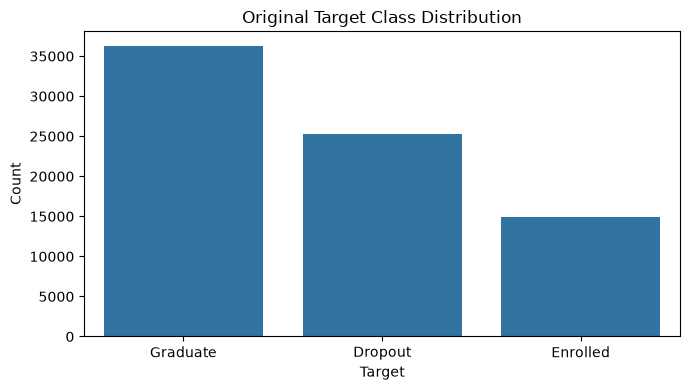

In [12]:
#print("Culomns Information:")
#train_df.info()

# print("null datas:")
# display(train_df.isnull().sum().sort_values(ascending=False).head(10))

print("Distribution of Target")
display(train_df["Target"].value_counts(dropna=False).rename("count").to_frame())

print("percentage of the Distribution of Target:")
display((100 * train_df["Target"].value_counts(normalize=True, dropna=False))
        .round(2).rename("percentage").to_frame())

plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x="Target", order=train_df["Target"].value_counts().index)
plt.title("Original Target Class Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 3.Converting the problem into a binary classification task 

اdim  Enrolled: (61578, 38)


,count
Target,
Graduate,36282
Dropout,25296


,percentage
Target,
Graduate,58.92
Dropout,41.08


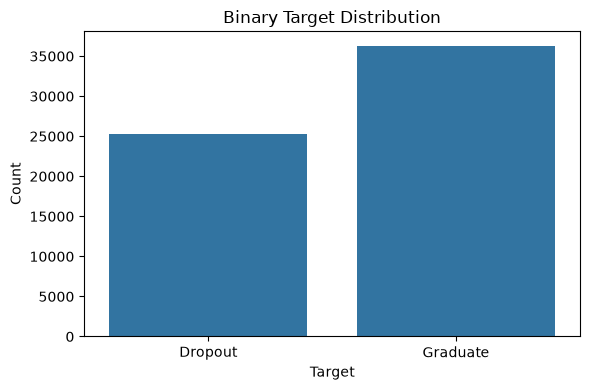

In [13]:
binary_df = train_df[train_df["Target"].isin(["Graduate", "Dropout"])].copy()

print("اdim  Enrolled:", binary_df.shape)
display(binary_df["Target"].value_counts().rename("count").to_frame())
display((100 * binary_df["Target"].value_counts(normalize=True))
        .round(2).rename("percentage").to_frame())

plt.figure(figsize=(6, 4))
sns.countplot(data=binary_df, x="Target", order=["Dropout", "Graduate"])
plt.title("Binary Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4.Feature Preparation and Data Splitting

In [14]:
drop_columns = ["Target", "id"]
X = binary_df.drop(columns=drop_columns, errors="ignore")
y = binary_df["Target"].map({"Graduate": 0, "Dropout": 1})

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("number of the Features:", X.shape[1])
print("dim of X_train:", X_train.shape)
print("dim of X_val:", X_val.shape)
print("possitive class ratio (Dropout):")
print("train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")

number of the Features: 36
dim of X_train: (49262, 36)
dim of X_val: (12316, 36)
possitive class ratio (Dropout):
train: 41.08 %
Validation: 41.08 %


## 5.Feature Scaling 

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Scaled training data format:", X_train_scaled.shape)
print("Validated training data format:", X_val_scaled.shape)

Scaled training data format: (49262, 36)
Validated training data format: (12316, 36)


## 6.Training and evaluating the base model with k=5

In [22]:
def evaluate_model(model, X_eval, y_true):
    y_pred = model.predict(X_eval)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }, y_pred



knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_5.fit(X_train_scaled, y_train)

metrics_5, y_pred_5 = evaluate_model(knn_5, X_val_scaled, y_val)

print("evaliuate with k=5 (possitive class: Dropout):")
for metric, value in metrics_5.items():
    print(f"{metric}: {value:.4f}")

print("Classification Report:")
print(classification_report(
    y_val, y_pred_5,
    labels=[0, 1],
    target_names=["Graduate", "Dropout"],
    zero_division=0
))

evaliuate with k=5 (possitive class: Dropout):
Accuracy: 0.9184
Precision: 0.9481
Recall: 0.8478
F1-Score: 0.8951
Classification Report:
              precision    recall  f1-score   support

    Graduate       0.90      0.97      0.93      7257
     Dropout       0.95      0.85      0.90      5059

    accuracy                           0.92     12316
   macro avg       0.92      0.91      0.91     12316
weighted avg       0.92      0.92      0.92     12316



## 7.The Basic Matrix for (k=5)

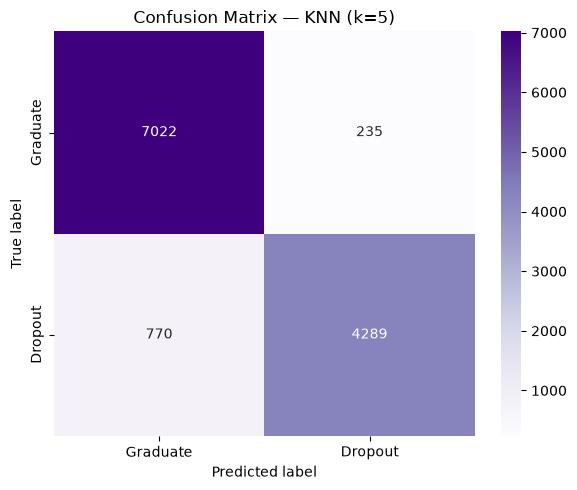

[[TN, FP],
 [FN, TP]]
TN (True Graduate Recognization): 7022
FP (False Graduate Prediction for Dropout): 235
FN (False Dropout Prediction for Graduate): 770
TP (True Dropout Recognization): 4289


In [24]:
cm_5 = confusion_matrix(y_val, y_pred_5, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_5, annot=True, fmt="d", cmap="Purples",
    xticklabels=["Graduate", "Dropout"],
    yticklabels=["Graduate", "Dropout"]
)
plt.title("Confusion Matrix — KNN (k=5)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

print("[[TN, FP],")
print(" [FN, TP]]")
print(f"TN (True Graduate Recognization): {cm_5[0, 0]}")
print(f"FP (False Graduate Prediction for Dropout): {cm_5[0, 1]}")
print(f"FN (False Dropout Prediction for Graduate): {cm_5[1, 0]}")
print(f"TP (True Dropout Recognization): {cm_5[1, 1]}")

## 8.Comparison Different Values for K

In [25]:
k_values = [3, 5, 7, 15, 25, 50]
results = []
models = {}

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    metrics, y_pred = evaluate_model(model, X_val_scaled, y_val)

    results.append({
        "k": k,
        **metrics
    })
    models[k] = model

results_df = pd.DataFrame(results).sort_values("k").reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}"
}))

,k,Accuracy,Precision,Recall,F1-Score
0,3,0.9166,0.9367,0.8547,0.8939
1,5,0.9184,0.9481,0.8478,0.8951
2,7,0.9205,0.9558,0.8456,0.8973
3,15,0.9219,0.9631,0.8421,0.8985
4,25,0.9192,0.9639,0.8346,0.8946
5,50,0.9171,0.9676,0.8259,0.8911


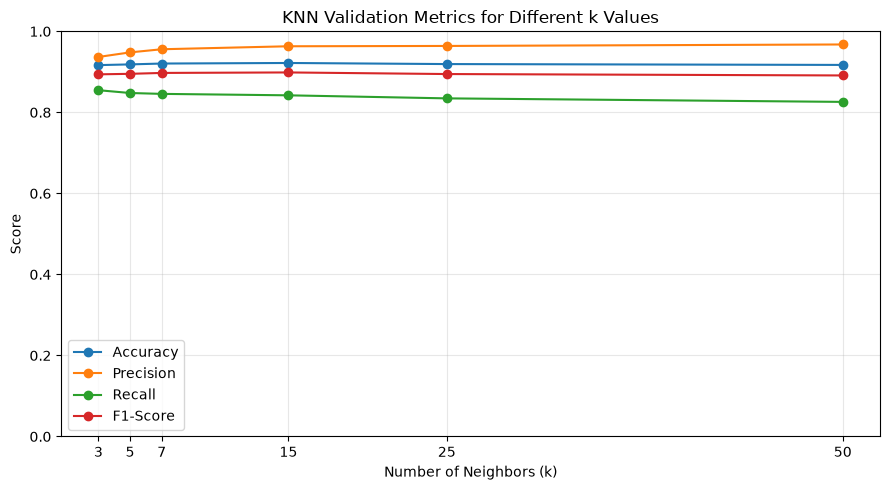

In [26]:
plt.figure(figsize=(9, 5))
for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    plt.plot(results_df["k"], results_df[metric], marker="o", label=metric)

plt.title("KNN Validation Metrics for Different k Values")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Score")
plt.xticks(k_values)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 9.ٍ Final Evaluation and Optimization for K    

 F1-Score: 15
Criteria for the final model:
Accuracy: 0.9219
Precision: 0.9631
Recall: 0.8421
F1-Score: 0.8985
Final Model Classification Report:
              precision    recall  f1-score   support

    Graduate       0.90      0.98      0.94      7257
     Dropout       0.96      0.84      0.90      5059

    accuracy                           0.92     12316
   macro avg       0.93      0.91      0.92     12316
weighted avg       0.93      0.92      0.92     12316



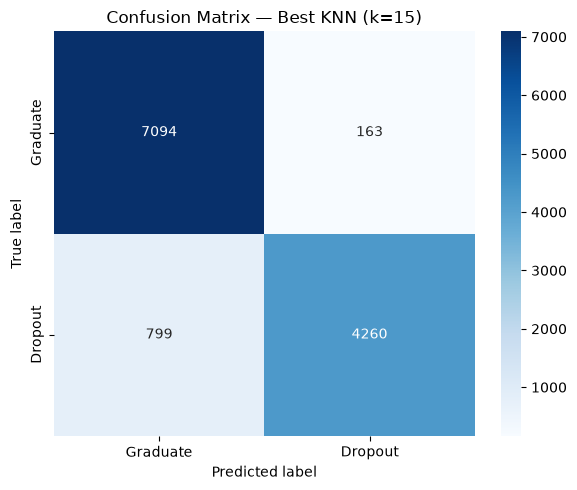

In [27]:
best_row = results_df.loc[results_df["F1-Score"].idxmax()]
best_k = int(best_row["k"])
best_model = models[best_k]
best_metrics, y_pred_best = evaluate_model(best_model, X_val_scaled, y_val)

print(f" F1-Score: {best_k}")
print("Criteria for the final model:")
for metric, value in best_metrics.items():
    print(f"{metric}: {value:.4f}")

print("Final Model Classification Report:")
print(classification_report(
    y_val, y_pred_best,
    labels=[0, 1],
    target_names=["Graduate", "Dropout"],
    zero_division=0
))

cm_best = confusion_matrix(y_val, y_pred_best, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_best, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Graduate", "Dropout"],
    yticklabels=["Graduate", "Dropout"]
)
plt.title(f"Confusion Matrix — Best KNN (k={best_k})")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

## 10.Observations and Conclusions

In [28]:
best_f1 = float(best_row["F1-Score"])
baseline_row = results_df.loc[results_df["k"] == 5].iloc[0]
baseline_f1 = float(baseline_row["F1-Score"])

print(
    f"1) best F1-Score is {best_f1:.4f} Related to k={best_k} .\n"
    f"2) for k=5 ,F1-Score model is {baseline_f1:.4f} .\n"
)

1) best F1-Score is 0.8985 Related to k=15 .
2) for k=5 ,F1-Score model is 0.8951 .

